# Persistent Homology of Urban Street Networks
### Topological Data Analysis via Level-Set Propagation and GUDHI

This notebook extracts a street network from OpenStreetMap, rasterizes it, constructs a signed distance function, propagates a level-set front via the Godunov upwind scheme, and computes persistent homology of the resulting arrival-time filtration using GUDHI. The topological features (connected components H0 and loops/holes H1) reveal the structure of the urban fabric.

## 1. Parameters

In [43]:
# --- Location & extraction ---
CENTER_POINT = (38.7120, -9.1300)    # Alfama, Lisbon (organic medieval fabric)
DIST_M = 500
IMG_SIZE     = 500                   # raster resolution (pixels)
STREET_WIDTH = 2                    # pixel width of drawn streets
#Estas dos son las config de Medellin que nos ejemplifican todo, dejemoslas ahí
#L1=42.33476181392957
#L2=-71.02793019104497
      
#CENTER_POINT = (L1,L2)    # Alfama, Lisbon (organic medieval fabric)
      
DIST_M       = 1000                   # extraction radius in meters
IMG_SIZE     = 1000                  # raster resolution (pixels)
STREET_WIDTH = 2                    # pixel width of drawn streets

# --- Propagation ---
V        = 1.0    # constant speed
DT       = 0.1   # time step (CFL: DT <= 0.5)
N_STEPS  = 1000    # total iterations

# --- Persistent homology ---
NUM_LANDSCAPES = 30
RESOLUTION = 500

print('Parameters configured ✓')

Parameters configured ✓


## 2. Install & Import Dependencies

In [44]:
!pip install osmnx matplotlib numpy scipy scikit-image gudhi --quiet

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import osmnx as ox
from scipy.ndimage import distance_transform_edt
from skimage.draw import line as draw_line
import gudhi
import warnings
warnings.filterwarnings('ignore')

# Style
plt.rcParams.update({
    'axes.facecolor': 'white',
    'figure.facecolor': 'white',
    'text.color': '#111111',
    'axes.labelcolor': '#111111',
    'xtick.color': '#111111',
    'ytick.color': '#111111',
})

print('Dependencies loaded ✓')

Dependencies loaded ✓


## 3. Extract Street Network from OSMnx

We center on **El Poblado, Medellín** — a dense, irregular urban fabric ideal for topological analysis.

In [45]:
print(f'Fetching street network around {CENTER_POINT} ...')
G = ox.graph_from_point(
    CENTER_POINT,
    dist=DIST_M,
    network_type='drive',
    retain_all=True 
)

# Project to UTM for metric coordinates
G_proj = ox.project_graph(G)
nodes, edges = ox.graph_to_gdfs(G_proj)

print(f'  Nodes: {len(nodes)}')
print(f'  Edges: {len(edges)}')

# Get bounding box in projected coordinates
x_min, y_min, x_max, y_max = (
    nodes.geometry.x.min(), nodes.geometry.y.min(),
    nodes.geometry.x.max(), nodes.geometry.y.max()
)
print(f'  Bounding box (m): Δx={x_max-x_min:.0f}, Δy={y_max-y_min:.0f}')

Fetching street network around (38.712, -9.13) ...
  Nodes: 481
  Edges: 889
  Bounding box (m): Δx=2002, Δy=1530


## 4. Rasterize the Street Network

Streets become the **initial zero-level set** φ = 0. The rest of the domain is initialized as open space (1.0).

Rasterized: (1000, 1000), street pixels: 152184


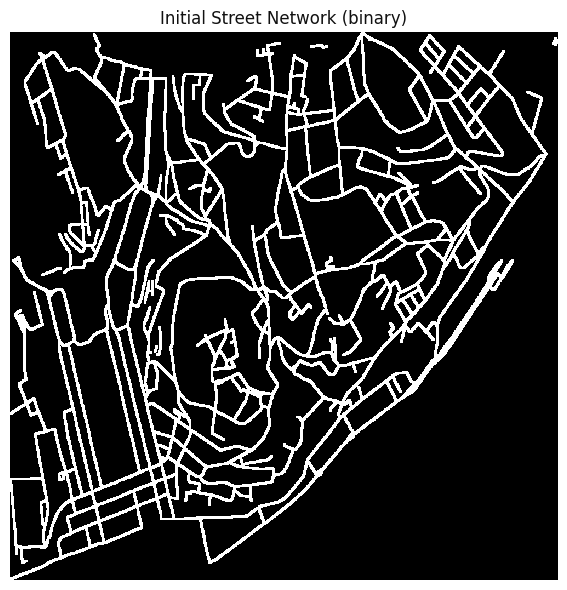

In [46]:
def rasterize_streets(edges, nodes, img_size, x_min, x_max, y_min, y_max, line_width=2):
    """
    Rasterize edge geometries into a binary image.
    Streets = 0 (black), open space = 1 (white).
    """
    canvas = np.ones((img_size, img_size), dtype=np.float32)

    def to_pixel(x, y):
        px = int((x - x_min) / (x_max - x_min) * (img_size - 1))
        py = int((y_max - y) / (y_max - y_min) * (img_size - 1))  # flip y
        return np.clip(px, 0, img_size-1), np.clip(py, 0, img_size-1)

    for _, edge in edges.iterrows():
        geom = edge.geometry
        if geom is None:
            continue
        coords = list(geom.coords)
        for i in range(len(coords) - 1):
            x0, y0 = to_pixel(*coords[i][:2])
            x1, y1 = to_pixel(*coords[i+1][:2])
            rr, cc = draw_line(y0, x0, y1, x1)
            # thicken the line
            for dy in range(-line_width, line_width+1):
                for dx in range(-line_width, line_width+1):
                    nr = np.clip(rr+dy, 0, img_size-1)
                    nc = np.clip(cc+dx, 0, img_size-1)
                    canvas[nr, nc] = 0.0

    return canvas

street_binary = rasterize_streets(
    edges, nodes, IMG_SIZE,
    x_min, x_max, y_min, y_max,
    line_width=STREET_WIDTH
)

print(f'Rasterized: {street_binary.shape}, street pixels: {int((street_binary==0).sum())}')

fig, ax = plt.subplots(1, 1, figsize=(6, 6))
ax.imshow(street_binary, cmap='bone_r', interpolation='nearest')
ax.set_title('Initial Street Network (binary)', color='#111111', fontsize=12)
ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Build Signed Distance Function

We compute the signed distance transform so the initial level set φ is:
- **Negative** at street pixels (φ = -distance_to_open_space)
- **Zero** at the street boundary
- **Positive** in open space (φ = +distance_to_street)

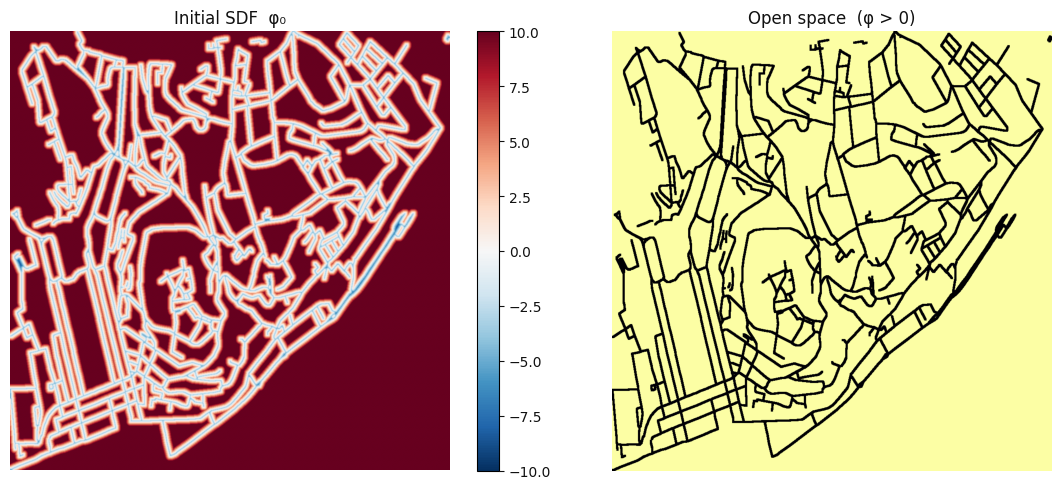

SDF range: [-8.5, 431.0]


In [47]:
def build_sdf(binary_img):
    """
    Given binary image where streets=0 and open=1,
    build a signed distance function:
      phi < 0  → inside street mask
      phi > 0  → open urban space
    """
    street_mask = (binary_img == 0)
    open_mask   = (binary_img == 1)

    # Distance from open pixels to nearest street
    dist_from_street = distance_transform_edt(open_mask)
    # Distance from street pixels to nearest open space
    dist_from_open   = distance_transform_edt(street_mask)

    # Signed: positive outside (open space), negative inside (street)
    phi = dist_from_street.astype(float) - dist_from_open.astype(float)
    return phi

phi0 = build_sdf(street_binary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
im0 = axes[0].imshow(phi0, cmap='RdBu_r', vmin=-10, vmax=10)
axes[0].set_title('Initial SDF  φ₀', color='#111111')
axes[0].axis('off')
plt.colorbar(im0, ax=axes[0], fraction=0.046)

im1 = axes[1].imshow(phi0 > 0, cmap='inferno')
axes[1].set_title('Open space  (φ > 0)', color='#111111')
axes[1].axis('off')
plt.tight_layout()
plt.show()

print(f'SDF range: [{phi0.min():.1f}, {phi0.max():.1f}]')

## 6. Level-Set Propagation — Godunov Scheme

We propagate the level set with the **Eikonal equation**: ∂φ/∂t + v|∇φ| = 0, using the Godunov upwind scheme with forward Euler time stepping.

In [ ]:
def godunov_grad_mag(phi, v_sign):
    """
    Godunov upwind scheme for |∇φ|.
    v_sign: +1 (expand outward) or -1 (contract inward).
    Returns |∇φ| for each cell.
    """
    # Forward / backward finite differences
    phi_p_x = np.zeros_like(phi)   # forward x
    phi_n_x = np.zeros_like(phi)   # backward x
    phi_p_y = np.zeros_like(phi)   # forward y
    phi_n_y = np.zeros_like(phi)   # backward y

    phi_p_x[:, :-1] = phi[:, 1:] - phi[:, :-1]
    phi_n_x[:, 1:]  = phi[:, 1:] - phi[:, :-1]
    phi_p_y[:-1, :] = phi[1:, :] - phi[:-1, :]
    phi_n_y[1:, :]  = phi[1:, :] - phi[:-1, :]

    if v_sign > 0:   # expanding front (speed > 0)
        Dx = np.maximum(np.maximum(phi_n_x, 0)**2, np.minimum(phi_p_x, 0)**2)
        Dy = np.maximum(np.maximum(phi_n_y, 0)**2, np.minimum(phi_p_y, 0)**2)
    else:            # contracting front (speed < 0)
        Dx = np.maximum(np.minimum(phi_n_x, 0)**2, np.maximum(phi_p_x, 0)**2)
        Dy = np.maximum(np.minimum(phi_n_y, 0)**2, np.maximum(phi_p_y, 0)**2)

    return np.sqrt(Dx + Dy)


def advance_level_set(phi, dt=0.4, v=1.0):
    """
    One time step of  ∂φ/∂t + v|∇φ| = 0.
    With v > 0 and outward convention the front moves
    from streets into open space.
    """
    grad_mag = godunov_grad_mag(phi, v_sign=np.sign(v))
    phi_new = phi - dt * v * grad_mag
    return phi_new

print('Level-set functions defined ✓')

Level-set functions defined ✓


## 7. Run Propagation & Compute Arrival-Time Map

The arrival-time map τ(i,j) records the first time step at which the propagating front reaches each pixel (φ ≤ 0). Street pixels receive τ = 0.

1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0
1.0


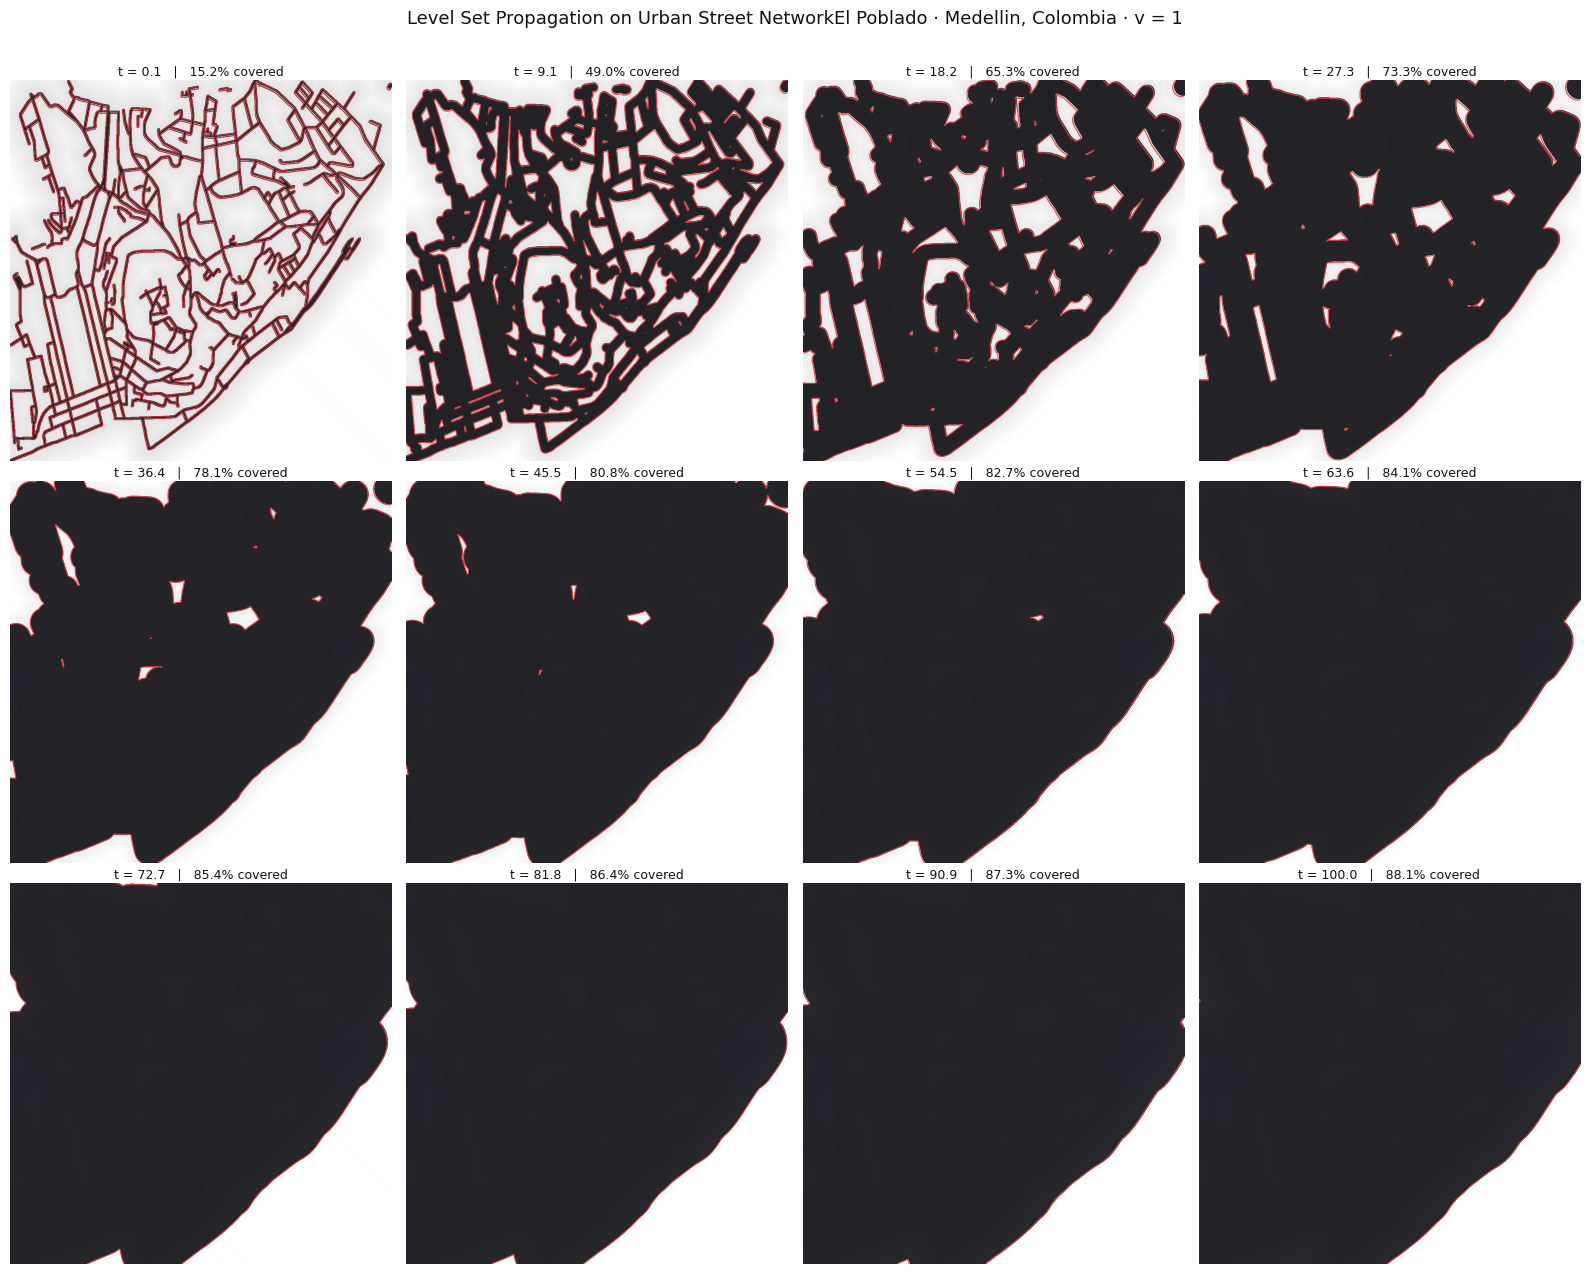

Saved → levelset_propagation_steps.png


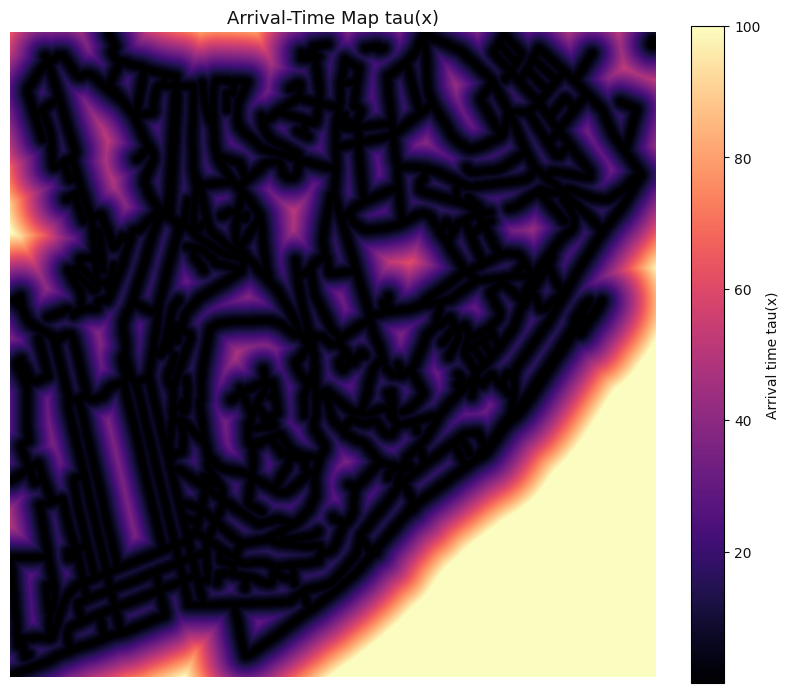

In [57]:
# Initialize arrival-time map with infinity (unreached)
arrival_time_map = np.full((IMG_SIZE, IMG_SIZE), np.inf, dtype=np.float64)

# Street pixels (phi0 <= 0) get arrival time 0
arrival_time_map[phi0 <= 0] = 0.0

phi = phi0.copy()

# Keep evenly spaced front snapshots for visualization (at least 10 when possible)
num_snapshots = min(N_STEPS, max(10, 12))
SNAPSHOT_STEPS = np.unique(np.linspace(1, N_STEPS, num=num_snapshots, dtype=int)).tolist()
snapshot_lookup = set(SNAPSHOT_STEPS)
snapshots = {}

for step in range(1, N_STEPS + 1):
    phi = advance_level_set(phi, dt=DT, v=V)

    # Record arrival time for newly reached pixels
    newly_reached = (phi <= 0) & (arrival_time_map == np.inf)
    arrival_time_map[newly_reached] = step * DT

    if step in snapshot_lookup:
        snapshots[step] = phi.copy()

# Any pixel still unreached gets the max propagation time
max_time = N_STEPS * DT
arrival_time_map[arrival_time_map == np.inf] = max_time

print('Propagation complete ✓')
print(f'Arrival time range: [{arrival_time_map.min():.2f}, {arrival_time_map.max():.2f}]')

# Visualize propagation fronts over time
SNAPSHOT_STEPS = sorted(snapshots.keys())
N_SNAP = len(SNAPSHOT_STEPS)
ncols = 4
nrows = int(np.ceil(N_SNAP / ncols))

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(ncols * 4, nrows * 4.2),
    facecolor='white'
)
axes = np.atleast_1d(axes).ravel()

for idx, step in enumerate(SNAPSHOT_STEPS):
    ax = axes[idx]
    phi_s = snapshots[step]
    T = step * DT

    # Filled region (phi <= 0 means reached by the front)
    reached = phi_s <= 0

    # Faint background reference
    ax.imshow(phi0, cmap='gray', alpha=0.15, vmin=-30, vmax=80)

    # Fill depth in reached region
    fill_display = np.where(reached, -phi_s, np.nan)
    ax.imshow(
        fill_display,
        cmap='inferno',
        alpha=0.85,
        vmin=0,
        vmax=max(phi0.max() * 0.9, 1e-6)
    )

    # Current front and street skeleton
    ax.contour(phi_s, levels=[0], colors=['#e63946'], linewidths=[0.8], alpha=0.9)
    ax.contour(street_binary, levels=[0.5], colors=['#222222'], linewidths=[0.4], alpha=0.5)

    coverage = 100.0 * reached.sum() / reached.size
    ax.set_title(f't = {T:.1f}   |   {coverage:.1f}% covered', color='#111111', fontsize=9, pad=4)
    ax.set_facecolor('white')
    ax.axis('off')

# Hide unused panels
for j in range(N_SNAP, len(axes)):
    axes[j].set_visible(False)

fig.suptitle(
    'Level Set Propagation on Urban Street Network'
    'El Poblado · Medellin, Colombia · v = 1',
    color='#111111',
    fontsize=13,
    y=1.01
)
plt.tight_layout()
#plt.savefig('grid_chicago/levelset_propagation_steps.pdf', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Saved → levelset_propagation_steps.png')

# Visualize arrival-time map
fig, ax = plt.subplots(1, 1, figsize=(8, 8))

# Create a custom colormap: street pixels (tau=0) in black, rest sequential
cmap = plt.cm.magma.copy()
cmap.set_under('black')
im = ax.imshow(arrival_time_map, cmap=cmap, vmin=0.001, interpolation='bilinear')
plt.colorbar(im, ax=ax, label='Arrival time tau(x)', fraction=0.046)
ax.set_title('Arrival-Time Map tau(x)', color='#111111', fontsize=13)
ax.axis('off')
plt.tight_layout()
#plt.savefig('grid_chicago/arrival_time_map.pdf', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()

## 8. Persistent Homology via GUDHI

We feed the arrival-time map into `gudhi.CubicalComplex` to compute persistent homology in dimensions 0 (connected components) and 1 (loops/holes).

In [50]:
def compute_persistence(arrival_time_map, dt=1.0, min_h1_steps=0):

    """
    Compute persistent homology of the arrival-time filtration.

    - H0: keep all nonzero-lifetime features, including essential
      components with death = inf.

    - H1: keep finite features with lifetime strictly greater than
      min_h1_steps * dt.
    """

    cc = gudhi.CubicalComplex(

        dimensions=arrival_time_map.shape,
        top_dimensional_cells=arrival_time_map.flatten()

    )

    cc.persistence()

    min_h1_lifetime = min_h1_steps * dt

    pairs_h0 = []
    pairs_h1 = []

    for dim, (b, d) in cc.persistence():
        if dim == 0:
            if d == float('inf'):
                # Keep essential connected components.
                pairs_h0.append((b, d))

                continue
            lifetime = d - b
            if lifetime <= 0:
                continue
            pairs_h0.append((b, d))

        elif dim == 1:
            if d == float('inf'):
                continue
            lifetime = d - b

            if lifetime <= 0:
                continue
            if lifetime > min_h1_lifetime:

                pairs_h1.append((b, d))

    return pairs_h0, pairs_h1


pairs_h0, pairs_h1 = compute_persistence(arrival_time_map, dt=DT, min_h1_steps=10)


print(f'H0 features (connected components, including essential): {len(pairs_h0)}')
print(f'H1 features (loops/holes) with lifetime > 5 steps: {len(pairs_h1)}')

inf_death_cap = arrival_time_map.max() * 1.05 if arrival_time_map.max() > 0 else 1.0

H0 features (connected components, including essential): 7
H1 features (loops/holes) with lifetime > 5 steps: 246


## 9. Persistence Diagrams

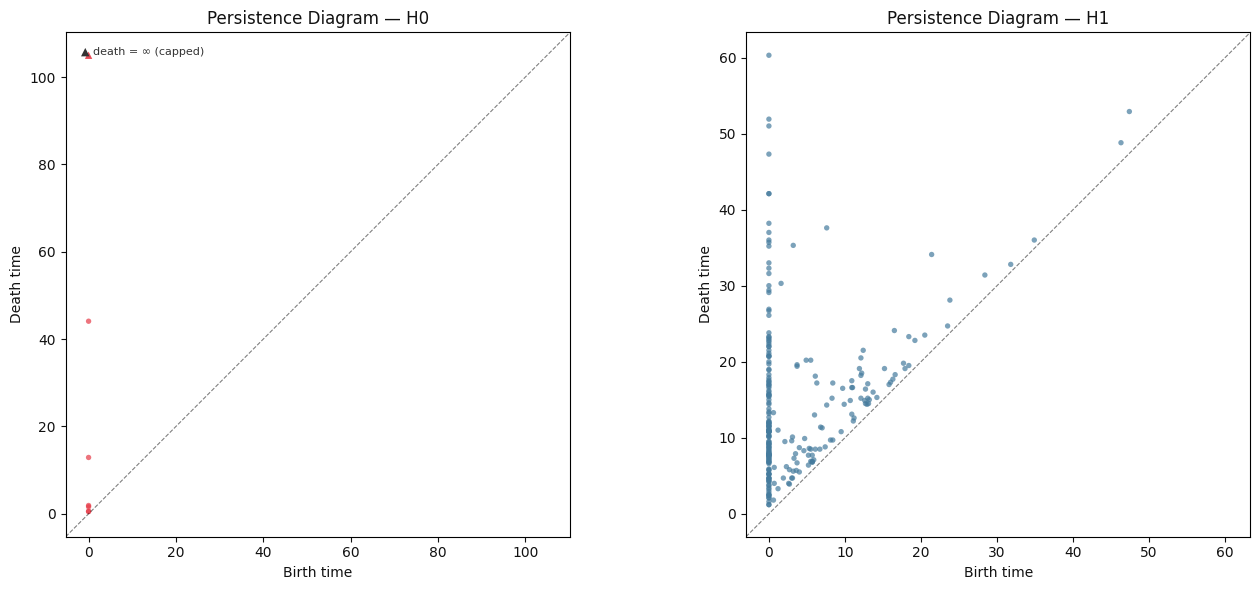

In [51]:
def plot_persistence_diagrams(pairs_h0, pairs_h1, inf_death_cap=None):

    """
    Scatter plot of (birth, death) pairs for H0 and H1 as subplots.
    Essential features (death = inf) are shown with triangular markers
    at a capped y-value.
    """

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    for ax, pairs, dim, color in [
        (axes[0], pairs_h0, 0, '#e63946'),
        (axes[1], pairs_h1, 1, '#457b9d'),

    ]:
        finite_pairs = [(b, d) for b, d in pairs if np.isfinite(d)]
        essential_pairs = [(b, d) for b, d in pairs if not np.isfinite(d)]

        finite_births = [b for b, _ in finite_pairs]
        finite_deaths = [d for _, d in finite_pairs]
        essential_births = [b for b, _ in essential_pairs]

        reference_vals = finite_births + finite_deaths + essential_births
        if reference_vals:
            lo, hi = min(reference_vals), max(reference_vals)

        else:
            lo, hi = 0.0, 1.0

        local_cap = hi + max(0.5, 0.05 * (hi - lo if hi > lo else 1.0))
        cap = inf_death_cap if inf_death_cap is not None else local_cap

        if finite_pairs:
            ax.scatter(finite_births, finite_deaths, s=15, alpha=0.7,
                       color=color, edgecolors='none')

        if essential_pairs:
            ax.scatter(essential_births, [cap] * len(essential_pairs), s=28,
                       marker='^', alpha=0.9, color=color, edgecolors='none')
            ax.text(0.03, 0.97, '▲ death = ∞ (capped)', transform=ax.transAxes,
                    va='top', fontsize=8, color='#333333')

        all_vals = reference_vals + ([cap] if essential_pairs else [])
        if not all_vals:
            all_vals = [0.0, 1.0]

        lo_plot, hi_plot = min(all_vals), max(all_vals)
        margin = (hi_plot - lo_plot) * 0.05 if hi_plot > lo_plot else 0.5

        ax.plot([lo_plot - margin, hi_plot + margin], [lo_plot - margin, hi_plot + margin],

                'k--', linewidth=0.8, alpha=0.5)

        ax.set_xlim(lo_plot - margin, hi_plot + margin)
        ax.set_ylim(lo_plot - margin, hi_plot + margin)
        ax.set_xlabel('Birth time')
        ax.set_ylabel('Death time')
        ax.set_title(f'Persistence Diagram — H{dim}')
        ax.set_aspect('equal')



    plt.tight_layout()
    #plt.savefig('grid_chicago/persistence_diagrams.pdf', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

plot_persistence_diagrams(pairs_h0, pairs_h1, inf_death_cap=inf_death_cap)



In [52]:
from pathlib import Path

def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
np.savetxt(NOTEBOOK_DIR / "grid.csv", pairs_h1, delimiter=",")


## 10. Persistence Barcodes

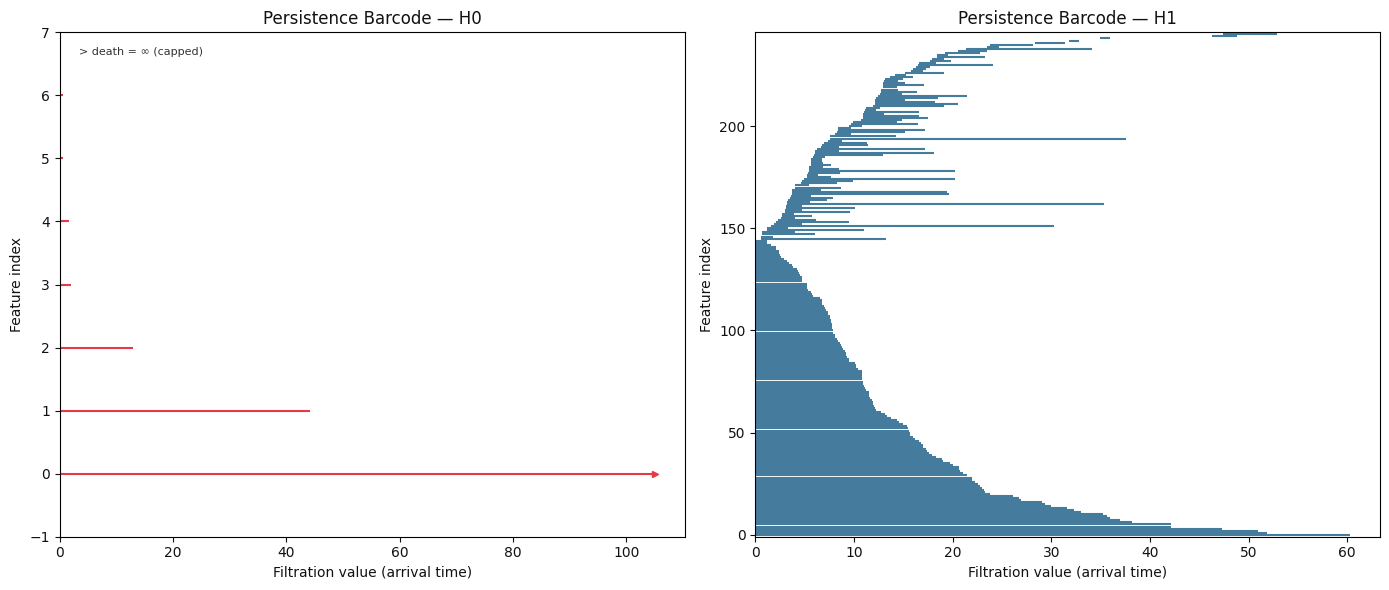

In [53]:
def plot_barcodes(pairs_h0, pairs_h1, inf_death_cap=None):

    """

    Horizontal line segments [birth, death) sorted by birth time.

    Essential features (death = inf) are capped and marked with arrowheads.

    Two subplots: H0 and H1.

    """

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))



    for ax, pairs, dim, color in [

        (axes[0], pairs_h0, 0, '#e63946'),

        (axes[1], pairs_h1, 1, '#457b9d'),

    ]:

        if pairs:

            sorted_pairs = sorted(pairs, key=lambda p: p[0])

            finite_vals = [v for pair in sorted_pairs for v in pair if np.isfinite(v)]

            if finite_vals:

                local_cap = max(finite_vals) + max(0.5, 0.05 * (max(finite_vals) - min(finite_vals) if max(finite_vals) > min(finite_vals) else 1.0))

            else:

                local_cap = 1.0

            cap = inf_death_cap if inf_death_cap is not None else local_cap



            x_vals = []

            has_essential = False

            for i, (b, d) in enumerate(sorted_pairs):

                d_plot = d if np.isfinite(d) else cap

                has_essential = has_essential or (not np.isfinite(d))

                x_vals.extend([b, d_plot])

                ax.plot([b, d_plot], [i, i], color=color, linewidth=1.5, solid_capstyle='butt')

                if not np.isfinite(d):

                    ax.plot(d_plot, i, marker='>', markersize=4, color=color)



            ax.set_ylim(-1, len(sorted_pairs))

            x_lo, x_hi = min(x_vals), max(x_vals)

            margin = (x_hi - x_lo) * 0.05 if x_hi > x_lo else 0.5

            ax.set_xlim(max(0.0, x_lo - margin), x_hi + margin)



            if has_essential:

                ax.text(0.03, 0.97, '> death = ∞ (capped)', transform=ax.transAxes,

                        va='top', fontsize=8, color='#333333')

        ax.set_xlabel('Filtration value (arrival time)')

        ax.set_ylabel('Feature index')

        ax.set_title(f'Persistence Barcode — H{dim}')



    plt.tight_layout()

    #plt.savefig('grid_chicago/persistence_barcodes.pdf', dpi=150, bbox_inches='tight', facecolor='white')

    plt.show()



plot_barcodes(pairs_h0, pairs_h1, inf_death_cap=inf_death_cap)



In [54]:
type(pairs_h1[0])

tuple

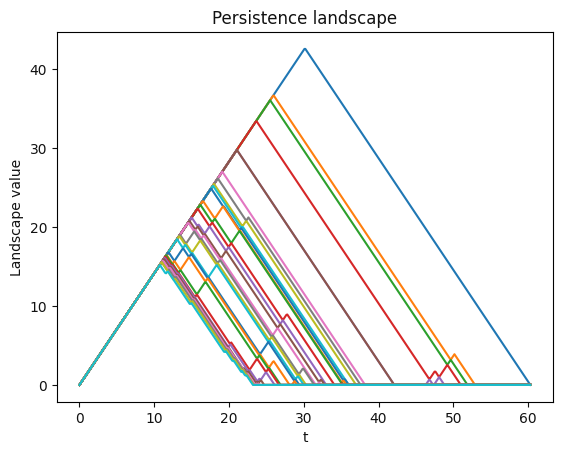

In [55]:
import numpy as np
import matplotlib.pyplot as plt
from gudhi.representations import Landscape

pairs_h1_ = np.array(pairs_h1, dtype=float)

L = Landscape(num_landscapes=NUM_LANDSCAPES, resolution=RESOLUTION, keep_endpoints=True)
L.fit([pairs_h1_])
vec = L.transform([pairs_h1_])[0]

landscapes = vec.reshape(L.num_landscapes, L.resolution)
x = L.grid_

for k in range(L.num_landscapes):
    plt.plot(x, landscapes[k])

np.savez(
    NOTEBOOK_DIR / "persistence_landscape_h1.npz",
    landscape_values=landscapes,   # shape: (num_landscapes, resolution)
    x_grid=x,                      # shape: (resolution,)
    flat_vector=vec,               # optional
    num_landscapes=L.num_landscapes,
    resolution=L.resolution
)

plt.xlabel("t")
plt.ylabel("Landscape value")
plt.title("Persistence landscape")
plt.show()

